<a href="https://colab.research.google.com/github/SaraLarkem/ireland-fuel-grocery-viz/blob/main/notebooks/04_Grocery_Subcategory_Disaggregation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 04: Perishable vs Shelf-stable Groceries

**Goal:** Find out if fresh foods (perishable) and long-lasting foods (shelf-stable) changed in price in different ways between 2016 and 2026, and compare both groups with fuel prices.

Notebooks 02 and 03 use the CSO's overall food price index. In this notebook we look at 14 single grocery items from the CSO, split them into two groups, and compare each group with petrol and diesel prices. The result is a supporting finding for the lag analysis in Notebook 05.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import os

# team colour scheme (same as Notebooks 02 and 03, used in every chart)
# the two grocery groups use two shades of the Food green
colours = {"Petrol": "#1F77B4", "Diesel": "#C26A1C", "Food": "#2CA02C",
           "Perishable": "#2CA02C", "Shelf-stable": "#98DF8A"}

# source line added to every chart
source_text = "Source: CSO Ireland, CPM24 (fuel) and CPM12 (grocery item prices)"

# Set style for consistency with final visualizations
plt.style.use('seaborn-v0_8-whitegrid')

# save charts and data to the repo's images/ and data/ folders (works from notebooks/ in VS Code or from the repo root)
IMG_DIR = "../images" if os.path.basename(os.getcwd()) == "notebooks" else "images"
DATA_DIR = "../data" if os.path.basename(os.getcwd()) == "notebooks" else "data"
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

# 1. Load both cleaned datasets directly from GitHub (outputs of Notebooks 01 and 01b)
base_url = 'https://raw.githubusercontent.com/SaraLarkem/ireland-fuel-grocery-viz/refs/heads/main/data/'
fuel_df = pd.read_csv(base_url + 'cleaned_fuel_grocery_data.csv')
sub_df = pd.read_csv(base_url + 'cleaned_grocery_subcategories.csv')

# 2. Standardise the date columns so the two files can be merged
fuel_df['Month_DT'] = pd.to_datetime(fuel_df['Month_DT'])
sub_df = sub_df.rename(columns={'Date': 'Month_DT'})
sub_df['Month_DT'] = pd.to_datetime(sub_df['Month_DT'])

# 3. Basic validation check - the group averages are only fair if every month has every item
print(f"Fuel data range: {fuel_df['Month_DT'].min().date()} to {fuel_df['Month_DT'].max().date()}")
print(f"Item data range: {sub_df['Month_DT'].min().date()} to {sub_df['Month_DT'].max().date()}")
print(f"Number of items: {sub_df['Item'].nunique()}")
print(f"Missing prices: {sub_df['Price'].isnull().sum()}")
print(f"Duplicate item-months: {sub_df.duplicated(subset=['Month_DT', 'Item']).sum()}")
print("Items per month (count of months):", sub_df.groupby('Month_DT').size().value_counts().to_dict())

Fuel data range: 2016-01-01 to 2026-09-01
Item data range: 2016-01-01 to 2026-10-01
Number of items: 14
Missing prices: 0
Duplicate item-months: 0
Items per month (count of months): {14: 130}


### 1. Grouping the Items
We split the 14 items into two groups of seven. The CSO does not group the items like this, so this is our own decision.

**Our rule:** an item is *perishable* if it goes off within about one or two weeks and needs to be moved quickly or kept cold. All other items are *shelf-stable*.

| Perishable (7) | Shelf-stable (7) |
|---|---|
| Bread, white sliced pan | Brown wholemeal flour |
| Butter | White self-raising flour |
| Full fat milk | Jam |
| Large eggs | Marmalade |
| Sirloin steak | White granulated sugar |
| Tomatoes | Tea bags |
| Uncooked chicken | Spaghetti |

* **Bread** is perishable because a sliced pan only lasts a few days.
* **Butter** is a borderline case. It lasts for weeks in the fridge, but it has to be kept cold during transport and in shops, so we put it in the perishable group.
* We do not call the perishable group "high-transport", because our data does not include any transport costs.

In [2]:
perishables = [
    'Bread, white sliced pan, large (800g)',
    'Butter per lb',
    'Full fat milk per 2 litre',
    'Large eggs per half dozen',
    'Sirloin steak per kg',
    'Tomatoes per kg',
    'Uncooked chicken medium size 1.6kg',
]

sub_df['Group'] = np.where(sub_df['Item'].isin(perishables), 'Perishable', 'Shelf-stable')

# Show which items ended up in each group
for group, items in sub_df.groupby('Group')['Item'].unique().items():
    print(f"{group} ({len(items)} items):")
    for item in sorted(items):
        print(f"  - {item}")

Perishable (7 items):
  - Bread, white sliced pan, large (800g)
  - Butter per lb
  - Full fat milk per 2 litre
  - Large eggs per half dozen
  - Sirloin steak per kg
  - Tomatoes per kg
  - Uncooked chicken medium size 1.6kg
Shelf-stable (7 items):
  - Brown, wholemeal flour per 2 kg
  - Jam per lb
  - Marmalade per lb
  - Spaghetti per 500g
  - Tea bags per 80
  - White granulated sugar per 1 kg
  - White, self raising flour per 2 kg


### 2. Turning Prices into an Index
The items have very different prices. Sirloin steak costs €14–22 per kg, but milk and eggs cost about €2. If we simply took the average of the euro prices, the expensive items would control the result: a €1 rise is only about 5% for steak, but about 50% for milk.

To make every item count equally, we turn each item's price into an index where **January 2016 = 100**. For example, a value of 120 means the item costs 20% more than in January 2016. Then we take the average of the seven indices in each group. This way we compare how much prices changed, not how expensive the items are.

In [3]:
# 1. Index each item to its own January 2016 price
base_prices = sub_df[sub_df['Month_DT'] == '2016-01-01'].set_index('Item')['Price']
sub_df['Item_Index'] = sub_df['Price'] / sub_df['Item'].map(base_prices) * 100

# 2. Average the item indices within each group, per month
group_df = sub_df.pivot_table(index='Month_DT', columns='Group',
                              values='Item_Index', aggfunc='mean').reset_index()

# 3. Merge with fuel data (inner join keeps only months present in both files)
merged_df = pd.merge(fuel_df, group_df, on='Month_DT', how='inner')
merged_df = merged_df.set_index('Month_DT').sort_index()

# 4. Check: both groups should start at exactly 100
print(f"Merged range: {merged_df.index.min().date()} to {merged_df.index.max().date()} ({len(merged_df)} months)")
print(merged_df[['Diesel', 'Petrol', 'Perishable', 'Shelf-stable']].head(3).round(1))

# 5. Change in each item over the whole period, to see which items move each group
latest = sub_df['Month_DT'].max()
item_change = (sub_df[sub_df['Month_DT'] == latest]
               .set_index('Item')[['Group', 'Item_Index']]
               .assign(Change_since_Jan_2016_pct=lambda d: (d['Item_Index'] - 100).round(1))
               .drop(columns='Item_Index')
               .sort_values(['Group', 'Change_since_Jan_2016_pct'], ascending=[True, False]))
print(f"\nPrice change by item, January 2016 to {latest:%B %Y}:")
print(item_change)

Merged range: 2016-01-01 to 2026-09-01 (129 months)
            Diesel  Petrol  Perishable  Shelf-stable
Month_DT                                            
2016-01-01    65.0    72.8       100.0         100.0
2016-02-01    61.1    70.5        98.9         100.6
2016-03-01    61.9    70.0        97.5         101.2

Price change by item, January 2016 to October 2026:
                                              Group  Change_since_Jan_2016_pct
Item                                                                          
Butter per lb                            Perishable                       57.8
Full fat milk per 2 litre                Perishable                       39.3
Sirloin steak per kg                     Perishable                       35.7
Large eggs per half dozen                Perishable                       34.2
Bread, white sliced pan, large (800g)    Perishable                       33.4
Tomatoes per kg                          Perishable                       25.

All seven perishable items cost more than in January 2016, with rises from about 24% (chicken) to about 58% (butter). The shelf-stable items are more mixed. Sugar, spaghetti and tea rose by 24–42%, the two flours and marmalade rose by less than 8%, and jam fell by about 20%. Each group has only seven items, so one item can change the group average a lot. Jam, for example, pulls the shelf-stable line down.

### 3. Fuel Prices vs Grocery Groups
Fuel prices and grocery prices use different starting points (fuel: December 2023 = 100; groceries: January 2016 = 100). So we show them in two separate panels, one above the other, with the same time axis. We do not put two y-axes on one chart, because the two scales could be stretched to make the lines look more (or less) connected than they really are. The grey areas show the event periods from Notebook 03.

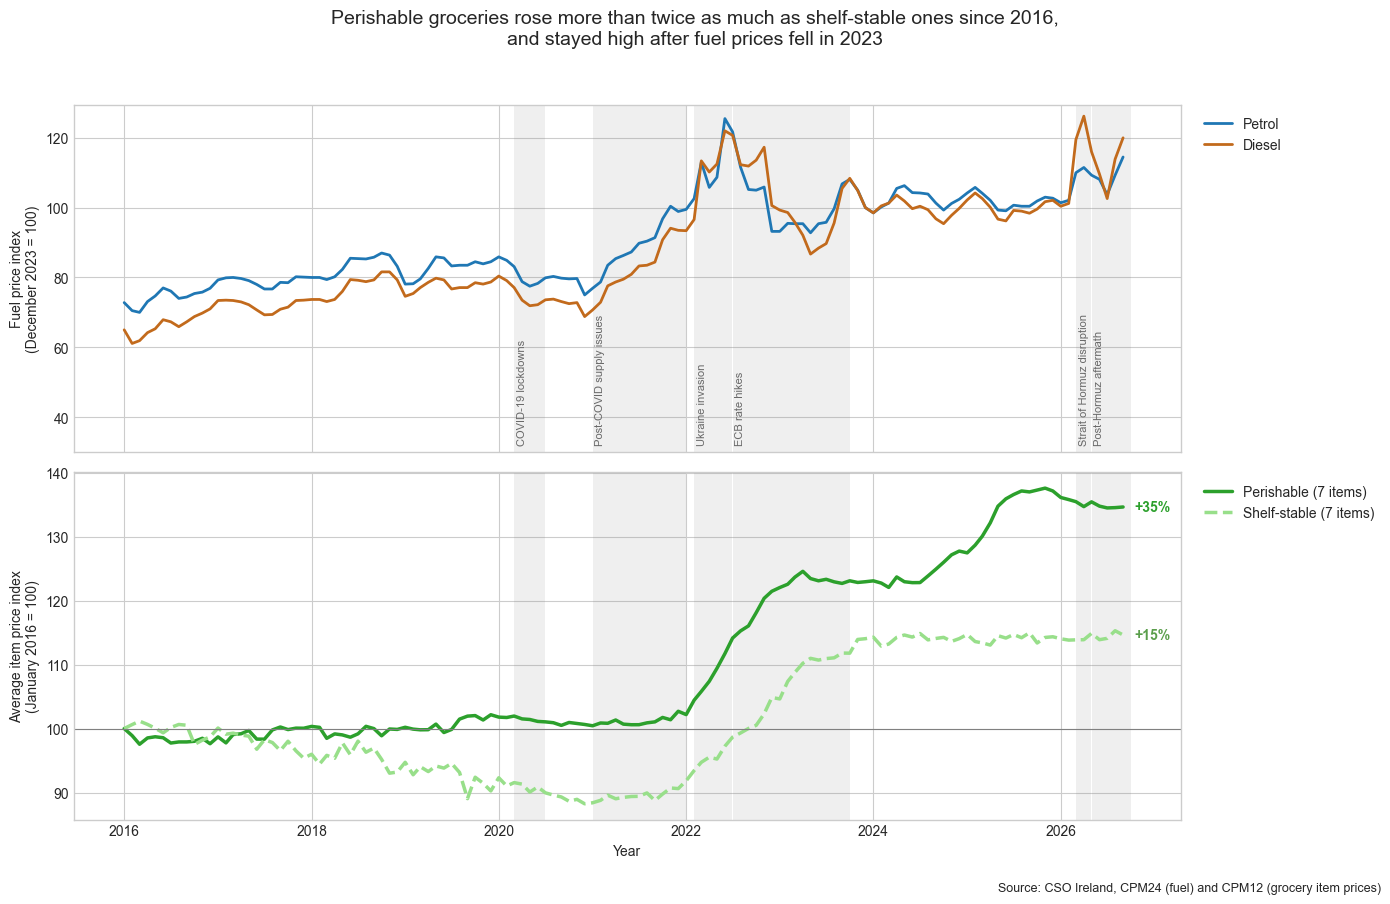

In [4]:
# Event windows - same dates as Notebook 03
events = {
    "COVID-19 lockdowns":          ("2020-03-01", "2020-06-30"),
    "Post-COVID supply issues":    ("2021-01-01", "2021-12-31"),
    "Ukraine invasion":            ("2022-02-01", "2022-06-30"),
    "ECB rate hikes":              ("2022-07-01", "2023-09-30"),
    "Strait of Hormuz disruption": ("2026-03-01", "2026-04-30"),
    "Post-Hormuz aftermath":       ("2026-05-01", "2026-09-30"),
}

fig, (ax_fuel, ax_food) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Top panel: fuel CPI
ax_fuel.plot(merged_df.index, merged_df['Petrol'], color=colours["Petrol"], linewidth=2, label='Petrol')
ax_fuel.plot(merged_df.index, merged_df['Diesel'], color=colours["Diesel"], linewidth=2, label='Diesel')
ax_fuel.set_ylabel('Fuel price index\n(December 2023 = 100)')
ax_fuel.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)

# Bottom panel: grocery groups
ax_food.plot(merged_df.index, merged_df['Perishable'], color=colours["Perishable"], linewidth=2.5, label='Perishable (7 items)')
ax_food.plot(merged_df.index, merged_df['Shelf-stable'], color=colours["Shelf-stable"], linewidth=2.5, linestyle='--', label='Shelf-stable (7 items)')
ax_food.axhline(100, color='grey', linewidth=0.8)
ax_food.set_ylabel('Average item price index\n(January 2016 = 100)')
ax_food.set_xlabel('Year')
ax_food.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=False)

# Shade event periods on both panels and label them once on the top panel
for ax in (ax_fuel, ax_food):
    for start, end in events.values():
        ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color='grey', alpha=0.12, linewidth=0)
# extra space under the fuel lines so the event labels don't cover them
ax_fuel.set_ylim(30, ax_fuel.get_ylim()[1])
for name, (start, end) in events.items():
    ax_fuel.text(pd.Timestamp(start) + pd.Timedelta(days=10), 32, name, rotation=90,
                 va='bottom', ha='left', fontsize=8, color='dimgrey')

# Annotate the gap between the two grocery groups at the end of the series
last = merged_df.index[-1]
p_last, s_last = merged_df.loc[last, 'Perishable'], merged_df.loc[last, 'Shelf-stable']
ax_food.annotate(f"+{p_last - 100:.0f}%", xy=(last, p_last), xytext=(8, 0), textcoords='offset points',
                 va='center', color=colours["Perishable"], fontweight='bold')
ax_food.annotate(f"+{s_last - 100:.0f}%", xy=(last, s_last), xytext=(8, 0), textcoords='offset points',
                 va='center', color='#5a9e4b', fontweight='bold')

fig.suptitle('Perishable groceries rose more than twice as much as shelf-stable ones since 2016,\n'
             'and stayed high after fuel prices fell in 2023', fontsize=14, y=0.99)

fig.text(0.99, 0.01, source_text, ha="right", fontsize=9)
plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.savefig(f"{IMG_DIR}/grocery_groups_perishable_vs_shelf_stable.png", dpi=300, bbox_inches="tight")
plt.show()

From 2016 to 2021, both grocery groups changed very little. Perishable items stayed close to 100, and shelf-stable items slowly fell to about 88 by the end of 2020. Fuel prices started to rise in early 2021 and reached a peak in mid-2022. Both grocery groups started to rise in early 2022, about a year after fuel.

When fuel prices fell again in late 2022 and 2023, grocery prices did not fall. Perishable items kept rising to about 137 by late 2025, and shelf-stable items stayed at about 114 from 2024 onwards. Fuel prices jumped again during the 2026 Strait of Hormuz disruption, but neither grocery group has risen so far (data up to September 2026).

The timing fits the idea of a delay between fuel and food prices, which we test in Notebook 05. However, this chart alone does not show that fuel prices caused the grocery price rises.

### 4. Findings and Limitations
**Findings**
* Since January 2016, perishable items rose by about 35% on average and shelf-stable items by about 15%. Perishable items rose more than twice as much.
* Both groups started rising in 2022, about a year after fuel prices started rising in early 2021. Neither group fell when fuel prices went down in 2023.
* Neither group has risen after the 2026 Strait of Hormuz fuel price jump so far. We only have a few months of data after the jump, so it is too early to say if a later rise will follow.

These results show that the series are linked, not that one causes the other. Other costs also went up in the same period, such as wages, energy for food processing and refrigeration, packaging, and world prices for products like milk and grain. Any of these could explain part of the difference between the two groups.

**Limitations**
* Each group is a simple average of only seven items. The official CPI gives different weights to different items, but we do not. One item can move a group a lot (jam fell by about 20%).
* The split into perishable and shelf-stable is our own decision (see Section 1). Moving butter or bread to the other group would change the results.
* The prices are national averages, so they do not show differences between regions or between cheap and expensive brands.
* The Hormuz period is only two months long, and the period after it is only five months long. This is too short to make strong conclusions about the 2026 events.

### 5. Passing the Data to the Final Visualizations
We save the monthly group indices together with the fuel data.
* **Notebook 06** uses this file for the chart that shows which groceries react to fuel prices.

In [5]:
# Save the group indices for Notebook 06
export_path = f"{DATA_DIR}/04_grocery_groups_output.csv"

df_export = merged_df[['Petrol', 'Diesel', 'Food and non-alcoholic beverages', 'Perishable', 'Shelf-stable']]
df_export.to_csv(export_path)

print(f"Grocery group analysis complete. Dataset exported to: {export_path}")

Grocery group analysis complete. Dataset exported to: ../data/04_grocery_groups_output.csv
